[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nahuelcosta/generative-networks/blob/main/transformers/fundamentals.ipynb)

This notebooks is part of the [Generative Networks course](https://www.nahuelcosta.com/teaching/generative-networks).

# Transformer Fundamentals

This tutorial turns the main ideas behind Transformers into small, inspectable experiments. We will:

- build a byte-level Byte Pair Encoding (BPE) tokenizer;
- compare token IDs, one-hot vectors, and learned embeddings;
- calculate scaled dot-product attention by hand;
- see exactly what a causal mask changes;
- use multi-head attention;
- compare sinusoidal, learned, and rotary positional information.

## 0. Dependencies

In [1]:
# Install only missing packages. Colab and most course environments already provide them.
import importlib.util
import subprocess
import sys

packages = {"torch": "torch", "matplotlib": "matplotlib", "numpy": "numpy"}
missing = [pip_name for import_name, pip_name in packages.items()
           if importlib.util.find_spec(import_name) is None]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


## 1. Imports and Reproducibility

In [2]:
import math
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. From Text to Token IDs

Neural networks receive numbers, not strings. A **tokenizer** converts text into a sequence of categorical token IDs. The value of an ID is only an address in a vocabulary: token 240 is not more important than token 12.

Modern tokenizers often use subword units. We will implement a compact **byte-level BPE** tokenizer:

1. Encode text as UTF-8 bytes, giving a fixed base vocabulary of IDs `0..255`.
2. Count adjacent token pairs.
3. Replace the most frequent pair with a new token.
4. Repeat.

Starting from bytes means any Unicode text can be represented without an unknown token. Production tokenizers add details such as regex pre-tokenization, special tokens, optimized training, and carefully specified whitespace behavior.

In [3]:
def count_pairs(token_ids):
    return Counter(zip(token_ids, token_ids[1:]))


def merge_pair(token_ids, pair, new_id):
    """Replace every non-overlapping occurrence of pair with new_id."""
    merged = []
    i = 0
    while i < len(token_ids):
        if i + 1 < len(token_ids) and (token_ids[i], token_ids[i + 1]) == pair:
            merged.append(new_id)
            i += 2
        else:
            merged.append(token_ids[i])
            i += 1
    return merged


def train_byte_bpe(text, num_merges):
    token_ids = list(text.encode("utf-8"))
    merges = []
    history = [len(token_ids)]

    for merge_index in range(num_merges):
        counts = count_pairs(token_ids)
        if not counts:
            break
        best_count = max(counts.values())
        # Lexicographic tie-breaking makes training deterministic.
        best_pair = min(pair for pair, count in counts.items() if count == best_count)
        new_id = 256 + merge_index
        token_ids = merge_pair(token_ids, best_pair, new_id)
        merges.append((best_pair, new_id, best_count))
        history.append(len(token_ids))

    return token_ids, merges, history

In [4]:
training_text = (
    "Attention connects tokens with context. "
    "Attention can connect distant tokens. "
    "¡La atención también funciona con Unicode! 🚀 "
) * 6

original_bytes = list(training_text.encode("utf-8"))
bpe_ids, learned_merges, token_counts = train_byte_bpe(training_text, num_merges=20)

print(f"UTF-8 bytes: {len(original_bytes)}")
print(f"BPE tokens:  {len(bpe_ids)}")
print("First five learned merges:")
for pair, new_id, count in learned_merges[:5]:
    print(f"  {pair} -> {new_id} (frequency {count})")

assert len(learned_merges) == 20
assert [new_id for _, new_id, _ in learned_merges] == list(range(256, 276))

UTF-8 bytes: 774
BPE tokens:  438
First five learned merges:
  (111, 110) -> 256 (frequency 42)
  (32, 99) -> 257 (frequency 30)
  (101, 110) -> 258 (frequency 30)
  (257, 256) -> 259 (frequency 24)
  (32, 116) -> 260 (frequency 18)


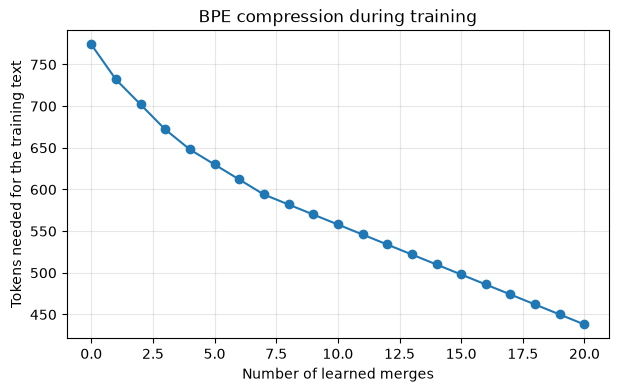

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(range(len(token_counts)), token_counts, marker="o")
plt.xlabel("Number of learned merges")
plt.ylabel("Tokens needed for the training text")
plt.title("BPE compression during training")
plt.grid(alpha=0.3)
plt.show()

### Encoding and Decoding

The order of the learned merge rules is part of the tokenizer. To decode, every new token recursively expands into the byte sequence from which it was built.

In [6]:
def encode_with_merges(text, merges):
    token_ids = list(text.encode("utf-8"))
    for pair, new_id, _ in merges:
        token_ids = merge_pair(token_ids, pair, new_id)
    return token_ids


def build_byte_vocabulary(merges):
    vocabulary = {token_id: bytes([token_id]) for token_id in range(256)}
    for (left, right), new_id, _ in merges:
        vocabulary[new_id] = vocabulary[left] + vocabulary[right]
    return vocabulary


def decode_with_vocabulary(token_ids, vocabulary):
    return b"".join(vocabulary[token_id] for token_id in token_ids).decode("utf-8")


byte_vocabulary = build_byte_vocabulary(learned_merges)
unicode_example = "¡Transformers relacionan tokens lejanos! 🤖"
encoded_example = encode_with_merges(unicode_example, learned_merges)
decoded_example = decode_with_vocabulary(encoded_example, byte_vocabulary)

print("Text:   ", unicode_example)
print("Tokens: ", encoded_example)
print("Decoded:", decoded_example)
assert decoded_example == unicode_example
assert all(token_id in byte_vocabulary for token_id in encoded_example)

Text:    ¡Transformers relacionan tokens lejanos! 🤖
Tokens:  [194, 161, 84, 114, 265, 115, 102, 111, 114, 109, 101, 114, 115, 32, 114, 101, 108, 97, 99, 261, 265, 274, 115, 32, 108, 101, 106, 265, 111, 115, 33, 32, 240, 159, 164, 150]
Decoded: ¡Transformers relacionan tokens lejanos! 🤖


## 3. Token IDs, One-Hot Vectors, and Embeddings

One-hot vectors avoid assigning an ordinal meaning to IDs, but they are sparse and every pair of distinct tokens is equally distant. An embedding table stores one trainable dense vector per token. During learning, tokens useful in similar contexts can acquire related representations.

Looking up rows in `nn.Embedding` is mathematically equivalent to multiplying one-hot vectors by the embedding weight matrix, but without constructing the large sparse matrix.

In [7]:
vocab_size = 8
embedding_dim = 4
token_ids = torch.tensor([[1, 4, 1, 7]])
embedding = nn.Embedding(vocab_size, embedding_dim)

lookup_vectors = embedding(token_ids)
one_hot = F.one_hot(token_ids, num_classes=vocab_size).float()
matrix_vectors = one_hot @ embedding.weight

print("Token IDs shape: ", tuple(token_ids.shape))
print("One-hot shape:   ", tuple(one_hot.shape))
print("Embedding shape: ", tuple(lookup_vectors.shape))
print(lookup_vectors)

assert lookup_vectors.shape == (1, 4, embedding_dim)
assert torch.allclose(lookup_vectors, matrix_vectors)

Token IDs shape:  (1, 4)
One-hot shape:    (1, 4, 8)
Embedding shape:  (1, 4, 4)
tensor([[[ 0.6784, -1.2345, -0.0431, -1.6047],
         [ 1.6423, -0.1596, -0.4974,  0.4396],
         [ 0.6784, -1.2345, -0.0431, -1.6047],
         [-0.2316,  0.0418, -0.2516,  0.8599]]], grad_fn=<EmbeddingBackward0>)


## 4. From Recurrent Attention to Transformer Self-Attention

Attention was introduced as **additive encoder–decoder attention**: a recurrent decoder learned which encoder states mattered for its current output. The Transformer removed recurrence and used attention as its main sequence-processing operation.

In Transformer self-attention, every token representation is projected in parallel into:

- a **query**: what this position is looking for;
- a **key**: what this position can be matched by;
- a **value**: the information this position contributes.

For matrices $Q$, $K$, and $V$:

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

The terms must be named carefully: $QK^\top/\sqrt{d_k}$ contains **attention scores**, softmax produces **attention weights**, and the weighted sum of $V$ produces the **contextualized output**.

In [8]:
words = ["the", "player", "showed", "cards"]
x = torch.tensor([
    [1.0, 0.0, 1.0, 0.0],
    [0.0, 1.0, 1.0, 0.0],
    [1.0, 1.0, 0.0, 0.0],
    [0.0, 1.0, 0.0, 1.0],
])

torch.manual_seed(SEED)
query_projection = nn.Linear(4, 4, bias=False)
key_projection = nn.Linear(4, 4, bias=False)
value_projection = nn.Linear(4, 4, bias=False)

Q = query_projection(x)
K = key_projection(x)
V = value_projection(x)
scores = Q @ K.T / math.sqrt(K.size(-1))
attention_weights = F.softmax(scores, dim=-1)
contextualized = attention_weights @ V

print("Q, K, V:", Q.shape, K.shape, V.shape)
print("Scores:", scores.shape)
print("Weights (rows sum to 1):\n", attention_weights)
print("Contextualized outputs:\n", contextualized)

assert scores.shape == (4, 4)
assert contextualized.shape == (4, 4)
assert torch.allclose(attention_weights.sum(dim=-1), torch.ones(4))

Q, K, V: torch.Size([4, 4]) torch.Size([4, 4]) torch.Size([4, 4])
Scores: torch.Size([4, 4])
Weights (rows sum to 1):
 tensor([[0.3167, 0.2686, 0.2317, 0.1830],
        [0.2829, 0.2468, 0.2525, 0.2178],
        [0.2898, 0.2286, 0.2654, 0.2162],
        [0.2352, 0.2077, 0.2805, 0.2766]], grad_fn=<SoftmaxBackward0>)
Contextualized outputs:
 tensor([[0.2301, 0.3219, 0.1859, 0.1945],
        [0.2476, 0.3260, 0.1834, 0.1704],
        [0.2560, 0.3244, 0.1839, 0.1742],
        [0.2763, 0.3298, 0.1822, 0.1344]], grad_fn=<MmBackward0>)


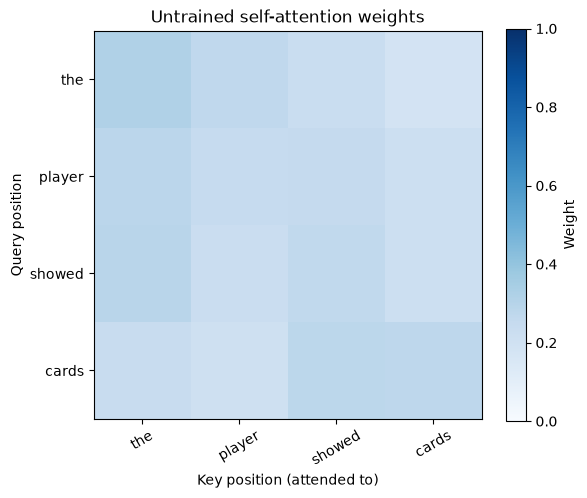

In [9]:
plt.figure(figsize=(6, 5))
plt.imshow(attention_weights.detach(), cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(len(words)), words, rotation=30)
plt.yticks(range(len(words)), words)
plt.xlabel("Key position (attended to)")
plt.ylabel("Query position")
plt.title("Untrained self-attention weights")
plt.colorbar(label="Weight")
plt.tight_layout()
plt.show()

## 5. Causal Masking

A decoder-only language model must not use future tokens when predicting the next token. Before softmax, it places $-\infty$ above the score matrix diagonal. Softmax converts those forbidden connections to exactly zero.

In [10]:
causal_mask = torch.triu(torch.ones_like(scores, dtype=torch.bool), diagonal=1)
masked_scores = scores.masked_fill(causal_mask, float("-inf"))
causal_weights = F.softmax(masked_scores, dim=-1)
causal_context = causal_weights @ V

print("Causal mask (True means blocked):\n", causal_mask)
print("Causal attention weights:\n", causal_weights)

assert torch.all(causal_weights[causal_mask] == 0)
assert torch.allclose(causal_weights.sum(dim=-1), torch.ones(4))
assert causal_context.shape == contextualized.shape

Causal mask (True means blocked):
 tensor([[False,  True,  True,  True],
        [False, False,  True,  True],
        [False, False, False,  True],
        [False, False, False, False]])
Causal attention weights:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.5341, 0.4659, 0.0000, 0.0000],
        [0.3697, 0.2917, 0.3386, 0.0000],
        [0.2352, 0.2077, 0.2805, 0.2766]], grad_fn=<SoftmaxBackward0>)


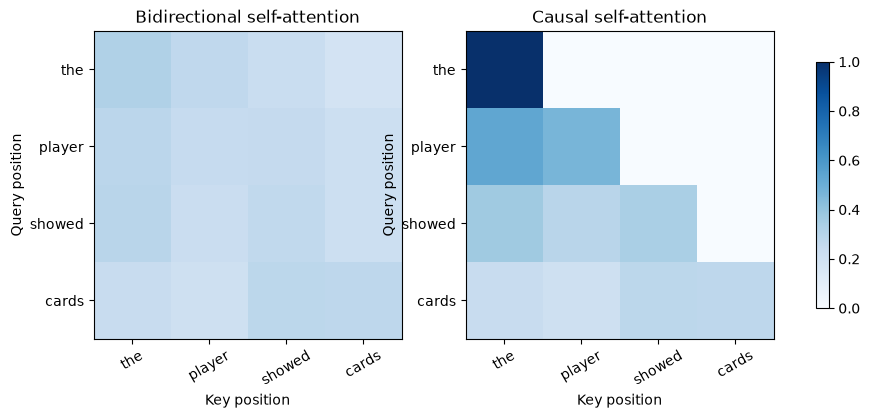

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, weights, title in zip(
    axes,
    [attention_weights, causal_weights],
    ["Bidirectional self-attention", "Causal self-attention"],
):
    image = axis.imshow(weights.detach(), cmap="Blues", vmin=0, vmax=1)
    axis.set_xticks(range(len(words)), words, rotation=30)
    axis.set_yticks(range(len(words)), words)
    axis.set_title(title)
    axis.set_xlabel("Key position")
    axis.set_ylabel("Query position")
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()

## 6. Multi-Head Attention

One attention head creates one learned view of token relationships. Multi-head attention projects the representations into several smaller subspaces, performs attention in parallel, concatenates the head outputs, and applies one final projection.

We now use PyTorch's optimized module. Asking for per-head weights lets us inspect the extra head dimension.

In [12]:
batch = x.unsqueeze(0)  # [batch, sequence, d_model]
multihead = nn.MultiheadAttention(embed_dim=4, num_heads=2, batch_first=True)
multihead_output, per_head_weights = multihead(
    batch, batch, batch, need_weights=True, average_attn_weights=False
)

print("Input shape:       ", tuple(batch.shape))
print("Output shape:      ", tuple(multihead_output.shape))
print("Per-head weights:  ", tuple(per_head_weights.shape))

assert multihead_output.shape == (1, 4, 4)
assert per_head_weights.shape == (1, 2, 4, 4)
assert torch.allclose(per_head_weights.sum(dim=-1), torch.ones(1, 2, 4))

Input shape:        (1, 4, 4)
Output shape:       (1, 4, 4)
Per-head weights:   (1, 2, 4, 4)


## 7. What Else Is in a Transformer Block?

Attention mixes information **between positions**. A position-wise feed-forward network then transforms every position independently with the same weights. Residual connections preserve an information path around both sublayers; layer normalization stabilizes activations; dropout regularizes training.

A modern pre-normalized block can be summarized as:

1. `x = x + dropout(self_attention(layer_norm(x)))`
2. `x = x + dropout(feed_forward(layer_norm(x)))`

Stacking blocks increases the number of transformations while self-attention keeps the path between any two positions short.

In [13]:
encoder_layer = nn.TransformerEncoderLayer(
    d_model=32,
    nhead=4,
    dim_feedforward=128,
    dropout=0.1,
    activation="gelu",
    batch_first=True,
    norm_first=True,
)
tiny_stack = nn.TransformerEncoder(encoder_layer, num_layers=2, norm=nn.LayerNorm(32))
dummy_sequence = torch.randn(3, 10, 32)
stack_output = tiny_stack(dummy_sequence)
print("Transformer stack:", tuple(dummy_sequence.shape), "->", tuple(stack_output.shape))
assert stack_output.shape == dummy_sequence.shape

Transformer stack: (3, 10, 32) -> (3, 10, 32)


/tmp/ipykernel_17400/2521142686.py:10: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  tiny_stack = nn.TransformerEncoder(encoder_layer, num_layers=2, norm=nn.LayerNorm(32))


## 8. Why Positions Are Necessary

Plain self-attention has no built-in notion of first or last. If we permute the input positions, unmasked self-attention permutes its output in the same way. This property is called **permutation equivariance**.

In [14]:
def self_attention_without_positions(sequence):
    q = query_projection(sequence)
    k = key_projection(sequence)
    v = value_projection(sequence)
    weights = F.softmax(q @ k.T / math.sqrt(k.size(-1)), dim=-1)
    return weights @ v


permutation = torch.tensor([2, 0, 3, 1])
original_output = self_attention_without_positions(x)
permuted_output = self_attention_without_positions(x[permutation])

difference = (permuted_output - original_output[permutation]).abs().max()
print(f"Maximum equivariance error: {difference.item():.2e}")
assert torch.allclose(permuted_output, original_output[permutation], atol=1e-6)

Maximum equivariance error: 2.98e-08


### Sinusoidal Positional Encoding

The original Transformer adds fixed sine and cosine waves to token embeddings. Different dimensions use different frequencies:

$$PE_{(pos,2i)}=\sin\left(pos/10000^{2i/d_{model}}\right)$$
$$PE_{(pos,2i+1)}=\cos\left(pos/10000^{2i/d_{model}}\right)$$

Absolute numbers, normalized positions, and binary patterns can help build intuition about representing order, but sinusoidal encoding is not derived from a sequence of those attempted schemes.

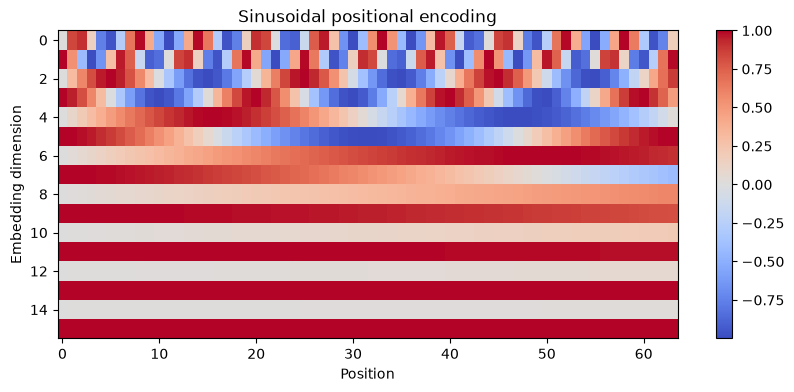

In [15]:
def sinusoidal_encoding(max_length, d_model):
    if d_model % 2 != 0:
        raise ValueError("d_model must be even")
    positions = torch.arange(max_length, dtype=torch.float32).unsqueeze(1)
    frequencies = torch.exp(
        torch.arange(0, d_model, 2, dtype=torch.float32)
        * (-math.log(10000.0) / d_model)
    )
    encoding = torch.zeros(max_length, d_model)
    encoding[:, 0::2] = torch.sin(positions * frequencies)
    encoding[:, 1::2] = torch.cos(positions * frequencies)
    return encoding


sinusoidal = sinusoidal_encoding(max_length=64, d_model=16)
plt.figure(figsize=(10, 4))
plt.imshow(sinusoidal.T, aspect="auto", cmap="coolwarm")
plt.xlabel("Position")
plt.ylabel("Embedding dimension")
plt.title("Sinusoidal positional encoding")
plt.colorbar()
plt.show()
assert sinusoidal.shape == (64, 16)

### Learned Positional Embeddings

Models such as GPT-2 and BERT learn a vector for each allowed position. This is simple and lets training choose the representation, but the table has a fixed maximum length and contains no trained entries beyond it.

In [16]:
token_embedding = nn.Embedding(100, 16)
position_embedding = nn.Embedding(64, 16)
example_ids = torch.tensor([[8, 3, 9, 3, 2]])
positions = torch.arange(example_ids.size(1))
model_input = token_embedding(example_ids) + position_embedding(positions)

print("Token embedding:   ", tuple(token_embedding(example_ids).shape))
print("Position embedding:", tuple(position_embedding(positions).shape))
print("Combined input:    ", tuple(model_input.shape))
assert model_input.shape == (1, 5, 16)

Token embedding:    (1, 5, 16)
Position embedding: (5, 16)
Combined input:     (1, 5, 16)


### Rotary Positional Embedding (RoPE)

RoPE applies position-dependent rotations to pairs of components in queries and keys—not values and not the input embeddings. Rotations preserve vector norms. More importantly,

$$(R_m q)^\top(R_n k)=q^\top R_{n-m}k,$$

so the attention dot product exposes the relative offset $n-m$. RoPE is flexible about sequence length, but good quality far beyond the trained context is not guaranteed; long-context models often rescale or otherwise adapt its frequencies. See [RoFormer](https://arxiv.org/abs/2104.09864).

In [17]:
def apply_rope(vector, positions, base=10000.0):
    """Rotate pairs in the last dimension according to integer positions."""
    d_model = vector.size(-1)
    if d_model % 2 != 0:
        raise ValueError("The final dimension must be even")
    frequencies = base ** (
        -torch.arange(0, d_model, 2, device=vector.device, dtype=vector.dtype) / d_model
    )
    angles = positions.to(vector.dtype).unsqueeze(-1) * frequencies
    cosines, sines = angles.cos(), angles.sin()
    pairs = vector.reshape(*vector.shape[:-1], d_model // 2, 2)
    even, odd = pairs[..., 0], pairs[..., 1]
    rotated = torch.stack(
        (even * cosines - odd * sines, even * sines + odd * cosines), dim=-1
    )
    return rotated.flatten(-2)


torch.manual_seed(SEED)
q = torch.randn(8)
k = torch.randn(8)
m, n, shift = 3, 11, 7

q_at_m = apply_rope(q, torch.tensor(m))
k_at_n = apply_rope(k, torch.tensor(n))
q_shifted = apply_rope(q, torch.tensor(m + shift))
k_shifted = apply_rope(k, torch.tensor(n + shift))

original_dot = q_at_m @ k_at_n
shifted_dot = q_shifted @ k_shifted
print(f"Norm before/after: {q.norm():.6f} / {q_at_m.norm():.6f}")
print(f"Dot product before/after common shift: {original_dot:.6f} / {shifted_dot:.6f}")

assert torch.allclose(q.norm(), q_at_m.norm(), atol=1e-6)
assert torch.allclose(original_dot, shifted_dot, atol=1e-5)

Norm before/after: 2.610880 / 2.610881
Dot product before/after common shift: -3.792150 / -3.792150


## 9. Training and Inference Are Different

A decoder-only model represents a sequence probability as

$$p(x_1,\dots,x_T)=\prod_{t=1}^{T}p(x_t\mid x_1,\dots,x_{t-1}).$$

During **teacher-forced training**, the known sequence is shifted into input/target pairs. A causal mask prevents leakage, so predictions for all positions can be computed in one parallel forward pass.

During **autoregressive inference**, the future is unknown. The model predicts one token, appends it to its input, and repeats. Training within a sequence is parallelizable; generation across new tokens remains sequential.

## 10. End-to-End Data Flow

The next notebook implements this complete path:

`text → UTF-8 bytes → BPE token IDs → token + position embeddings → repeated masked Transformer blocks → vocabulary logits → next-token probabilities`

Each Transformer block contains multi-head self-attention, a position-wise feed-forward network, residual paths, layer normalization, and dropout. In the final layer, one logit per vocabulary item is compared with the true next token using cross-entropy.

The original Transformer also has an encoder and cross-attention for sequence-to-sequence tasks such as translation. Our generative language model needs only the causal stack. Vision Transformers similarly turn image patches into an ordered sequence and add learned vectors that identify patch locations; training a ViT classifier is better treated as a later discriminative-vision exercise.

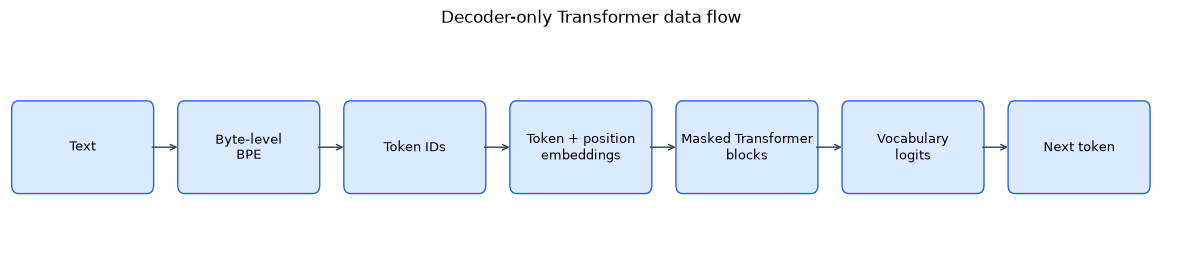

In [18]:
from matplotlib.patches import FancyBboxPatch

stages = [
    "Text", "Byte-level\nBPE", "Token IDs", "Token + position\nembeddings",
    "Masked Transformer\nblocks", "Vocabulary\nlogits", "Next token",
]
fig, axis = plt.subplots(figsize=(15, 2.8))
axis.set_xlim(0, len(stages) * 2)
axis.set_ylim(0, 2)
axis.axis("off")
for index, label in enumerate(stages):
    x_position = index * 2 + 0.1
    box = FancyBboxPatch(
        (x_position, 0.65), 1.55, 0.7,
        boxstyle="round,pad=0.08", facecolor="#dbeafe", edgecolor="#2563eb"
    )
    axis.add_patch(box)
    axis.text(x_position + 0.775, 1.0, label, ha="center", va="center", fontsize=9)
    if index < len(stages) - 1:
        axis.annotate("", xy=(x_position + 1.95, 1), xytext=(x_position + 1.58, 1),
                      arrowprops={"arrowstyle": "->", "color": "#334155"})
axis.set_title("Decoder-only Transformer data flow", pad=12)
plt.show()

## 11. Things to Try

- Increase the number of BPE merges and plot the compression tradeoff.
- Replace the random attention projections with hand-chosen matrices and predict the heatmap before running the cell.
- Compare the entropy of each multi-head attention distribution.
- Add sinusoidal positions before the permutation experiment and investigate which equality no longer holds.
- Change the shared RoPE shift and verify that only the relative offset matters.

## Troubleshooting

- If an attention row contains `nan`, make sure at least one key remains unmasked and apply the mask before softmax.
- If a BPE decode fails, preserve the learned merge order and build new vocabulary entries only after their children exist.
- If the RoPE check fails after modifying dimensions, keep the final dimension even and use the same frequencies for queries and keys.
- Random attention heatmaps have no semantic meaning before training; they demonstrate mechanics and shapes only.

**Primary references:** [Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473), [Attention Is All You Need](https://arxiv.org/html/1706.03762v7), and [RoFormer](https://arxiv.org/abs/2104.09864).